In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\maypa\Downloads\archive (4)\zomato.csv")
df.shape

(51717, 17)

In [3]:
df.isnull().sum().sort_values(ascending=False)

dish_liked                     28078
rate                            7775
phone                           1208
approx_cost(for two people)      346
rest_type                        227
cuisines                          45
location                          21
url                                0
address                            0
votes                              0
name                               0
online_order                       0
book_table                         0
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [4]:
df.dtypes

url                              str
address                          str
name                             str
online_order                     str
book_table                       str
rate                             str
votes                          int64
phone                            str
location                         str
rest_type                        str
dish_liked                       str
cuisines                         str
approx_cost(for two people)      str
reviews_list                     str
menu_item                        str
listed_in(type)                  str
listed_in(city)                  str
dtype: object

In [5]:
[features for features in df.columns if df[features].isnull().sum()>0]


['rate',
 'phone',
 'location',
 'rest_type',
 'dish_liked',
 'cuisines',
 'approx_cost(for two people)']

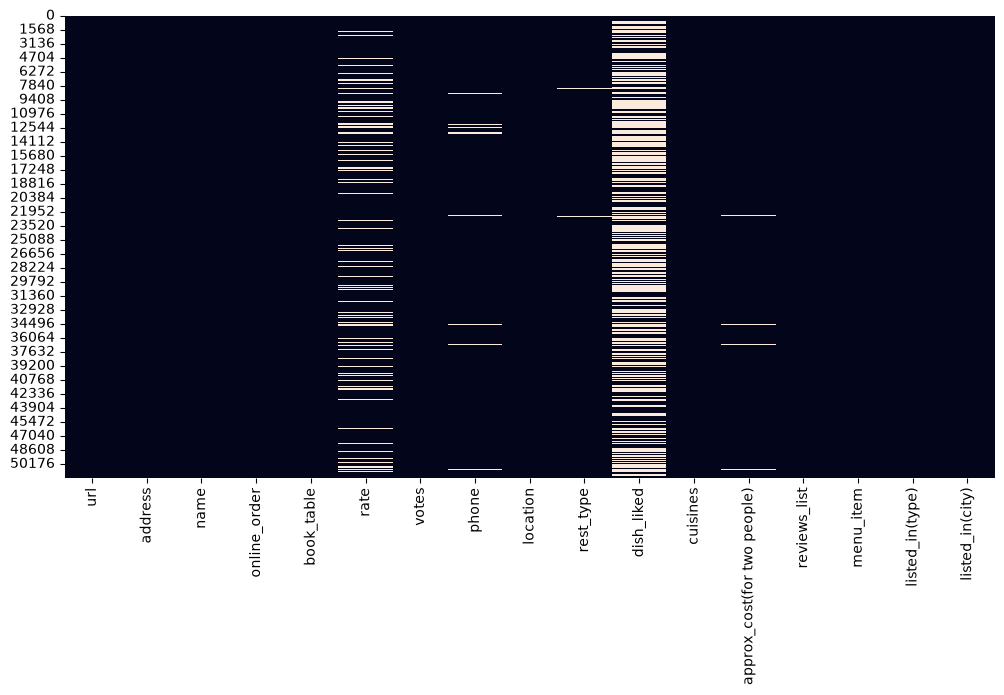

In [6]:
plt.figure(figsize=(12,6))
sns.heatmap(data=df.isnull(), cbar=False)
plt.show()


In [7]:
locations = df["listed_in(city)"].value_counts()

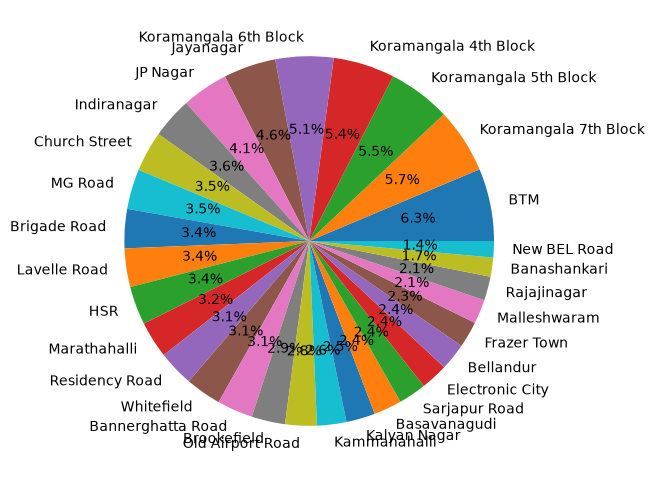

In [8]:
plt.figure(figsize=(6,6))
plt.pie(locations,labels=locations.index,autopct="%1.1f%%")
plt.show()

In [9]:
df.dtypes

url                              str
address                          str
name                             str
online_order                     str
book_table                       str
rate                             str
votes                          int64
phone                            str
location                         str
rest_type                        str
dish_liked                       str
cuisines                         str
approx_cost(for two people)      str
reviews_list                     str
menu_item                        str
listed_in(type)                  str
listed_in(city)                  str
dtype: object

In [10]:
df.groupby(["name", "location"]).size().reset_index().rename(columns={"name":"Name"})

,Name,location,0
0,#FeelTheROLL,Bellandur,2
1,#L-81 Cafe,HSR,9
2,#Vibes Restro,Electronic City,3
3,#refuel,Bannerghatta Road,3
4,'Brahmins' Thatte Idli,Basaveshwara Nagar,1
...,...,...,...
12135,nu.tree,Sarjapur Road,3
12136,nu.tree,Whitefield,4
12137,re:cess - Hilton Bangalore Embassy GolfLinks,Domlur,3
12138,repEAT Hub,Marathahalli,2


In [11]:
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='str')

In [12]:
df["reviews_list"]

0        [('Rated 4.0', 'RATED\n  A beautiful place to ...
1        [('Rated 4.0', 'RATED\n  Had been here for din...
2        [('Rated 3.0', "RATED\n  Ambience is not that ...
3        [('Rated 4.0', "RATED\n  Great food and proper...
4        [('Rated 4.0', 'RATED\n  Very good restaurant ...
                               ...                        
51712    [('Rated 5.0', "RATED\n  Food and service are ...
51713                                                   []
51714                                                   []
51715    [('Rated 4.0', 'RATED\n  Nice and friendly pla...
51716    [('Rated 5.0', 'RATED\n  Great ambience , look...
Name: reviews_list, Length: 51717, dtype: str

In [13]:
df[df["votes"]==0][["location"]] 

,location
72,Banashankari
75,Banashankari
84,Banashankari
90,Banashankari
91,Banashankari
...,...
51644,Brookefield
51675,Whitefield
51710,Whitefield
51713,Whitefield


In [14]:
df["votes"].value_counts(dropna=False).shape

(2328,)

In [15]:
df[["book_table","location"]].groupby(["book_table","location"]).size().reset_index().head()

,book_table,location,0
0,No,BTM,4956
1,No,Banashankari,842
2,No,Banaswadi,656
3,No,Bannerghatta Road,1531
4,No,Basavanagudi,668


In [16]:
df[df["book_table"]=="Yes"][["location"]].value_counts()

location             
Koramangala 5th Block    692
Indiranagar              454
MG Road                  347
Koramangala 4th Block    322
JP Nagar                 315
                        ... 
Yeshwantpur                2
Kaggadasapura              2
Kanakapura Road            1
RT Nagar                   1
Magadi Road                1
Name: count, Length: 66, dtype: int64

In [17]:
df[df["online_order"]=="Yes"][["location"]].value_counts()

location             
BTM                      3332
HSR                      1920
Koramangala 5th Block    1614
Jayanagar                1364
Indiranagar              1335
                         ... 
Hebbal                      4
Central Bangalore           3
Rajarajeshwari Nagar        2
Nagarbhavi                  2
West Bangalore              2
Name: count, Length: 90, dtype: int64

In [18]:
c = df["cuisines"].value_counts()

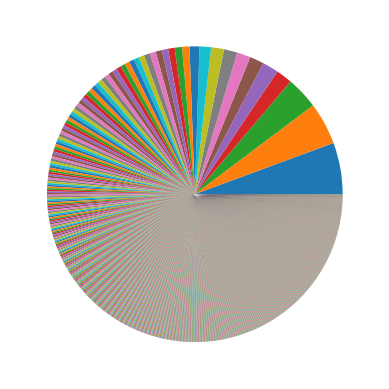

In [19]:
plt.pie(c,)
plt.show()